**Nama: Indah Putri Lestari**

**NIM: 2409116004**

**Kelas: A**

# **LIBRARY**

In [1]:
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import shapiro, normaltest, kstest, jarque_bera, chisquare, probplot, levene, ttest_ind, mannwhitneyu, f_oneway, pearsonr, wilcoxon, bartlett
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from statsmodels.graphics.regressionplots import plot_partregress_grid
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.diagnostic import het_breuschpagan, acorr_breusch_godfrey, het_goldfeldquandt
from statsmodels.stats.outliers_influence import variance_inflation_factor

# **DATASET 1**
BAB I, II, III, VII, VIII

In [2]:
df = pd.read_excel("/content/drive/MyDrive/PANDAS/Profile-of-Body-Metrics-and-Fashion-Colors.xlsx")

df

,Height(Centimeter),Weight(Kilograms),Gender,BMI,Skin Color,Clothes Color,Pants Color
0,167.089607,51.252494,Female,Underweight,"(226, 165, 137)","(19, 165, 16)","(24, 212, 123)"
1,181.648633,61.909547,Male,Ideal,"(204, 150, 103)","(55, 238, 252)","(101, 131, 136)"
2,176.272800,69.411778,Male,Ideal,"(226, 165, 137)","(58, 67, 207)","(27, 41, 168)"
3,173.270164,64.562199,Male,Ideal,"(119, 78, 58)","(29, 140, 46)","(71, 123, 25)"
4,172.181037,65.452010,Male,Ideal,"(226, 165, 137)","(200, 235, 99)","(122, 118, 117)"
...,...,...,...,...,...,...,...
24995,176.535461,53.538008,Female,Underweight,"(226, 165, 137)","(109, 113, 120)","(251, 24, 50)"
24996,163.952580,54.518674,Female,Ideal,"(119, 78, 58)","(71, 217, 148)","(82, 156, 212)"
24997,164.334317,53.644285,Female,Ideal,"(246, 215, 197)","(132, 65, 237)","(109, 93, 216)"
24998,171.524117,59.995797,Male,Ideal,"(246, 215, 197)","(134, 229, 242)","(126, 23, 219)"


In [3]:
print(df.head())

   Height(Centimeter)  Weight(Kilograms)  Gender          BMI  \
0          167.089607          51.252494  Female  Underweight   
1          181.648633          61.909547    Male        Ideal   
2          176.272800          69.411778    Male        Ideal   
3          173.270164          64.562199    Male        Ideal   
4          172.181037          65.452010    Male        Ideal   

        Skin Color   Clothes Color      Pants Color  
0  (226, 165, 137)   (19, 165, 16)   (24, 212, 123)  
1  (204, 150, 103)  (55, 238, 252)  (101, 131, 136)  
2  (226, 165, 137)   (58, 67, 207)    (27, 41, 168)  
3    (119, 78, 58)   (29, 140, 46)    (71, 123, 25)  
4  (226, 165, 137)  (200, 235, 99)  (122, 118, 117)  


In [4]:
print("\nTipe data setiap kolom dalam data ini: ")
df.dtypes


Tipe data setiap kolom dalam data ini: 


,0
Height(Centimeter),float64
Weight(Kilograms),float64
Gender,object
BMI,object
Skin Color,object
Clothes Color,object
Pants Color,object


In [5]:
print("\nStatistik deskriptif data ini: ")
df.describe()


Statistik deskriptif data ini: 


,Height(Centimeter),Weight(Kilograms)
count,25000.000000,25000.000000
mean,172.702509,57.642209
std,4.830264,5.289290
min,153.107034,35.386871
25%,169.429170,54.117461
50%,172.709078,57.677738
75%,175.953312,61.186318
max,190.888112,77.529759


# **DATASET 2**
BAB IV

In [6]:
df2 = pd.read_excel("/content/drive/MyDrive/PANDAS/before after.xlsx")

df2

,Date,Before breakfast,Before lunch,2h after lunch,Before dinner,2h after dinner
0,Wed. 9/Feb.,116.156923,157,132.504762,163,165.000
1,Thu. 10/Feb.,105.000000,155,132.504762,163,197.875
2,Fri. 11/Feb.,101.000000,138,132.504762,130,170.735
3,Sat. 12/Feb.,98.000000,123,132.504762,163,138.875
4,Sun. 13/Feb.,107.000000,157,132.504762,163,138.875
...,...,...,...,...,...,...
321,Tue. 27/Dec.,151.000000,157,132.504762,141,138.875
322,Wed. 28/Dec.,86.000000,84,132.504762,102,138.875
323,Thu. 29/Dec.,114.000000,92,132.504762,119,148.000
324,Fri. 30/Dec.,112.000000,129,132.504762,120,172.000


In [7]:
print(df2.head())

           Date  Before breakfast  Before lunch  2h after lunch  \
0   Wed. 9/Feb.        116.156923           157      132.504762   
1  Thu. 10/Feb.        105.000000           155      132.504762   
2  Fri. 11/Feb.        101.000000           138      132.504762   
3  Sat. 12/Feb.         98.000000           123      132.504762   
4  Sun. 13/Feb.        107.000000           157      132.504762   

   Before dinner  2h after dinner  
0            163          165.000  
1            163          197.875  
2            130          170.735  
3            163          138.875  
4            163          138.875  


In [8]:
print("\nTipe data setiap kolom dalam data ini: ")
df2.dtypes


Tipe data setiap kolom dalam data ini: 


,0
Date,object
Before breakfast,float64
Before lunch,int64
2h after lunch,float64
Before dinner,int64
2h after dinner,float64


In [9]:
print("\nStatistik deskriptif data ini: ")
df2.describe()


Statistik deskriptif data ini: 


,Before breakfast,Before lunch,2h after lunch,Before dinner,2h after dinner
count,326.000000,326.000000,3.260000e+02,326.000000,326.000000
mean,116.156923,94.837423,1.325048e+02,112.174847,169.431319
std,25.470043,24.730945,2.846540e-14,20.490225,17.930272
min,61.000000,52.000000,1.325048e+02,63.000000,138.875000
25%,97.000000,77.000000,1.325048e+02,98.000000,161.000000
50%,115.500000,89.000000,1.325048e+02,110.000000,170.735000
75%,132.750000,109.000000,1.325048e+02,124.000000,175.750000
max,182.000000,157.000000,1.325048e+02,163.000000,197.875000


# **DATASET 3**
BAB V

In [10]:
df3 = pd.read_excel("/content/drive/MyDrive/PANDAS/iris bersih.xlsx")

df3

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
142,6.7,3.0,5.2,2.3,Iris-virginica
143,6.3,2.5,5.0,1.9,Iris-virginica
144,6.5,3.0,5.2,2.0,Iris-virginica
145,6.2,3.4,5.4,2.3,Iris-virginica


In [11]:
print(df3.head())

   sepal_length  sepal_width  petal_length  petal_width      species
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa


In [12]:
print("\nTipe data setiap kolom dalam data ini: ")
df3.dtypes


Tipe data setiap kolom dalam data ini: 


,0
sepal_length,float64
sepal_width,float64
petal_length,float64
petal_width,float64
species,object


In [13]:
print("\nStatistik deskriptif data ini: ")
df3.describe()


Statistik deskriptif data ini: 


,sepal_length,sepal_width,petal_length,petal_width
count,147.000000,147.000000,147.000000,147.000000
mean,5.856463,3.052381,3.780272,1.208844
std,0.829100,0.426331,1.759111,0.757874
min,4.300000,2.050000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.400000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.050000,6.900000,2.500000


# **DATASET 4**
BAB IX

In [14]:
df4 = pd.read_csv("/content/drive/MyDrive/PANDAS/Fish.csv")

df4

,Species,Weight,Length1,Length2,Length3,Height,Width
0,Bream,242.0,23.2,25.4,30.0,11.5200,4.0200
1,Bream,290.0,24.0,26.3,31.2,12.4800,4.3056
2,Bream,340.0,23.9,26.5,31.1,12.3778,4.6961
3,Bream,363.0,26.3,29.0,33.5,12.7300,4.4555
4,Bream,430.0,26.5,29.0,34.0,12.4440,5.1340
...,...,...,...,...,...,...,...
154,Smelt,12.2,11.5,12.2,13.4,2.0904,1.3936
155,Smelt,13.4,11.7,12.4,13.5,2.4300,1.2690
156,Smelt,12.2,12.1,13.0,13.8,2.2770,1.2558
157,Smelt,19.7,13.2,14.3,15.2,2.8728,2.0672


In [15]:
print(df4.head())

  Species  Weight  Length1  Length2  Length3   Height   Width
0   Bream   242.0     23.2     25.4     30.0  11.5200  4.0200
1   Bream   290.0     24.0     26.3     31.2  12.4800  4.3056
2   Bream   340.0     23.9     26.5     31.1  12.3778  4.6961
3   Bream   363.0     26.3     29.0     33.5  12.7300  4.4555
4   Bream   430.0     26.5     29.0     34.0  12.4440  5.1340


In [16]:
print("\nTipe data setiap kolom dalam data ini: ")
df4.dtypes


Tipe data setiap kolom dalam data ini: 


,0
Species,object
Weight,float64
Length1,float64
Length2,float64
Length3,float64
Height,float64
Width,float64


In [17]:
print("\nStatistik deskriptif data ini: ")
df4.describe()


Statistik deskriptif data ini: 


,Weight,Length1,Length2,Length3,Height,Width
count,159.000000,159.000000,159.000000,159.000000,159.000000,159.000000
mean,398.326415,26.247170,28.415723,31.227044,8.970994,4.417486
std,357.978317,9.996441,10.716328,11.610246,4.286208,1.685804
min,0.000000,7.500000,8.400000,8.800000,1.728400,1.047600
25%,120.000000,19.050000,21.000000,23.150000,5.944800,3.385650
50%,273.000000,25.200000,27.300000,29.400000,7.786000,4.248500
75%,650.000000,32.700000,35.500000,39.650000,12.365900,5.584500
max,1650.000000,59.000000,63.400000,68.000000,18.957000,8.142000


# **DATASET 5**
BAB VI

In [18]:
df5 = pd.read_csv("/content/drive/MyDrive/PANDAS/Supplement_Sales_Weekly_Expanded.csv")

df5

,Date,Product Name,Category,Units Sold,Price,Revenue,Discount,Units Returned,Location,Platform
0,2020-01-06,Whey Protein,Protein,143,31.98,4573.14,0.03,2,Canada,Walmart
1,2020-01-06,Vitamin C,Vitamin,139,42.51,5908.89,0.04,0,UK,Amazon
2,2020-01-06,Fish Oil,Omega,161,12.91,2078.51,0.25,0,Canada,Amazon
3,2020-01-06,Multivitamin,Vitamin,140,16.07,2249.80,0.08,0,Canada,Walmart
4,2020-01-06,Pre-Workout,Performance,157,35.47,5568.79,0.25,3,Canada,iHerb
...,...,...,...,...,...,...,...,...,...,...
4379,2025-03-31,Melatonin,Sleep Aid,160,47.79,7646.40,0.21,1,USA,iHerb
4380,2025-03-31,Biotin,Vitamin,154,38.12,5870.48,0.22,1,UK,Walmart
4381,2025-03-31,Green Tea Extract,Fat Burner,139,20.40,2835.60,0.12,3,USA,iHerb
4382,2025-03-31,Iron Supplement,Mineral,154,18.31,2819.74,0.23,2,Canada,Amazon


In [19]:
print(df5.head())

         Date  Product Name     Category  Units Sold  Price  Revenue  \
0  2020-01-06  Whey Protein      Protein         143  31.98  4573.14   
1  2020-01-06     Vitamin C      Vitamin         139  42.51  5908.89   
2  2020-01-06      Fish Oil        Omega         161  12.91  2078.51   
3  2020-01-06  Multivitamin      Vitamin         140  16.07  2249.80   
4  2020-01-06   Pre-Workout  Performance         157  35.47  5568.79   

   Discount  Units Returned Location Platform  
0      0.03               2   Canada  Walmart  
1      0.04               0       UK   Amazon  
2      0.25               0   Canada   Amazon  
3      0.08               0   Canada  Walmart  
4      0.25               3   Canada    iHerb  


In [20]:
print("\nTipe data setiap kolom dalam data ini: ")
df5.dtypes


Tipe data setiap kolom dalam data ini: 


,0
Date,object
Product Name,object
Category,object
Units Sold,int64
Price,float64
Revenue,float64
Discount,float64
Units Returned,int64
Location,object
Platform,object


In [21]:
print("\nStatistik deskriptif data ini: ")
df5.describe()


Statistik deskriptif data ini: 


,Units Sold,Price,Revenue,Discount,Units Returned
count,4384.000000,4384.000000,4384.000000,4384.000000,4384.000000
mean,150.200274,34.781229,5226.569446,0.124398,1.531478
std,12.396099,14.198309,2192.491946,0.071792,1.258479
min,103.000000,10.000000,1284.000000,0.000000,0.000000
25%,142.000000,22.597500,3349.372500,0.060000,1.000000
50%,150.000000,34.720000,5173.140000,0.120000,1.000000
75%,158.000000,46.712500,7009.960000,0.190000,2.000000
max,194.000000,59.970000,10761.850000,0.250000,8.000000


# **BAB I UJI NORMALITAS DATA**

Text(0.5, 1.0, 'Histogram: Weight(Kilograms)')

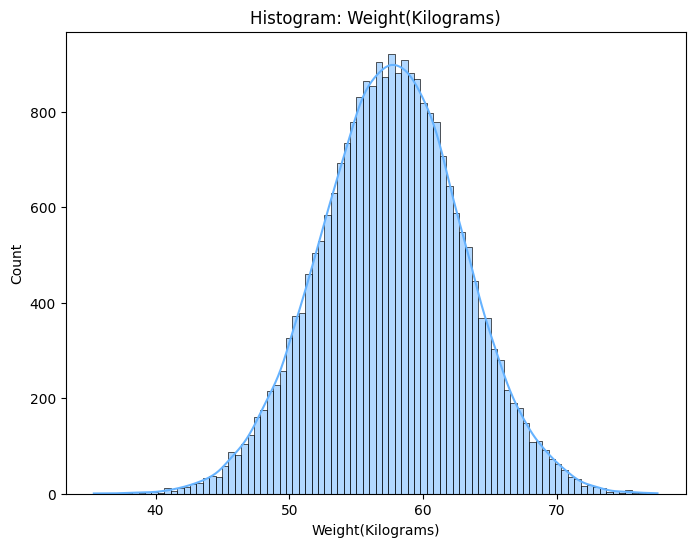

In [22]:
# Menggunakan histogram
plt.figure(figsize=(8, 6))
sns.histplot(data=df, x='Weight(Kilograms)', kde=True, color='#66b3ff')
plt.title('Histogram: Weight(Kilograms)')

Text(0.5, 1.0, 'Diagram Violin: Weight(Kilograms)')

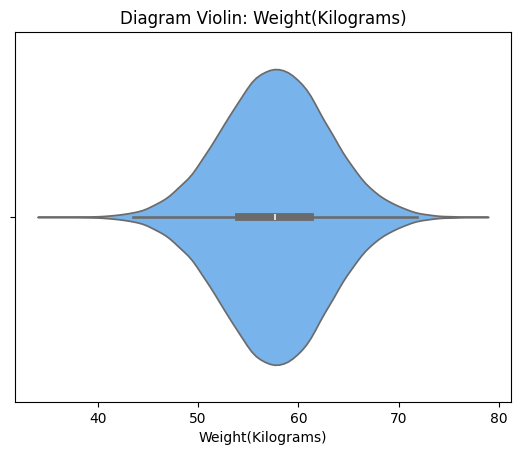

In [23]:
# Menggunakan diagram violin
sns.violinplot(x='Weight(Kilograms)', data=df, color='#66b3ff')
plt.title('Diagram Violin: Weight(Kilograms)')

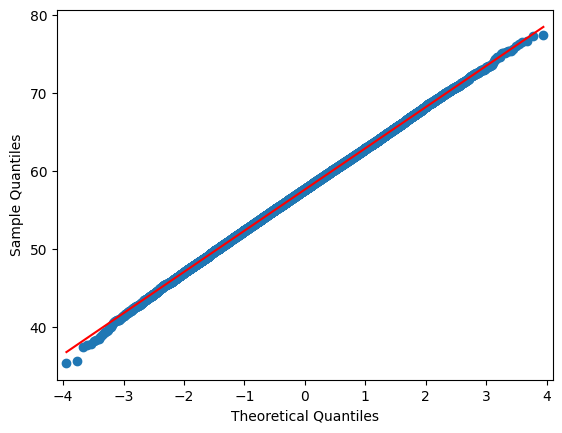

In [24]:
# Q-Q plot
sm.qqplot(df['Weight(Kilograms)'], line='s')
plt.show()

In [25]:
# Hipotesis:
# H0: Sampel berat badan manusia berdistribusi Normal.
# H1: Sampel berat badan manusia tidak berdistribusi Normal.

# Taraf signifikansi:
# Gunakan alpha = 5%.

# Uji statistik:
# Penelitian ini menggunakan statistik uji Shapiro-Wilk.

# Kriteria penolakan:
# H0 ditolak jika nilai P value < alpha.
stat, p = shapiro(df['Weight(Kilograms)'])
print('Statistik = %.3f, P value = %.3f' %(stat, p))
if p > 0.05:
  print('Sampel berat badan manusia Berdistribusi Normal (H0)')
else:
  print('Sampel berat badan manusia Tidak berdistribusi Normal (H1)')

Statistik = 1.000, P value = 0.396
Sampel berat badan manusia Berdistribusi Normal (H0)


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 25000.
  res = hypotest_fun_out(*samples, **kwds)


In [26]:
# Hipotesis:
# H0: Sampel berat badan manusia berdistribusi Normal.
# H1: Sampel berat badan manusia tidak berdistribusi Normal.

# Taraf signifikansi:
# Gunakan alpha = 5%.

# Uji statistik:
# Penelitian ini menggunakan statistik uji D'Agostino's K-squared test.

# Kriteria penolakan:
# H0 ditolak jika nilai P value < alpha.
stat, p = normaltest(df['Weight(Kilograms)'])
print('Statistik = %.3f, P value = %.3f' %(stat, p))
if p > 0.05:
  print('Sampel berat badan manusia Berdistribusi Normal (H0)')
else:
  print('Sampel berat badan manusia Tidak berdistribusi Normal (H1)')

Statistik = 4.865, P value = 0.088
Sampel berat badan manusia Berdistribusi Normal (H0)


In [27]:
# Hipotesis:
# H0: Sampel berat badan manusia berdistribusi Normal.
# H1: Sampel berat badan manusia tidak berdistribusi Normal.

# Taraf signifikansi:
# Gunakan alpha = 5%.

# Uji statistik:
# Penelitian ini menggunakan statistik uji Jarque-Bera.

# Kriteria penolakan:
# H0 ditolak jika nilai P value < alpha.
stat, p = jarque_bera(df['Weight(Kilograms)'])
print('Statistik = %.3f, P value = %.3f' %(stat, p))
if p > 0.05:
  print('Sampel berat badan manusia Berdistribusi Normal (H0)')
else:
  print('Sampel berat badan manusia Tidak berdistribusi Normal (H1)')

Statistik = 4.885, P value = 0.087
Sampel berat badan manusia Berdistribusi Normal (H0)


In [28]:
# Hipotesis:
# H0: Sampel berat badan manusia berdistribusi Normal.
# H1: Sampel berat badan manusia tidak berdistribusi Normal.

# Taraf signifikansi:
# Gunakan alpha = 5%.

# Uji statistik:
# Penelitian ini menggunakan statistik uji Chisquare.

# Kriteria penolakan:
# H0 ditolak jika nilai P value < alpha.
stat, p = chisquare(df['Weight(Kilograms)'])
print('Statistik = %.3f, P value = %.3f' %(stat, p))
if p > 0.05:
  print('Sampel berat badan manusia Berdistribusi Normal (H0)')
else:
  print('Sampel berat badan manusia Tidak berdistribusi Normal (H1)')

Statistik = 12133.239, P value = 1.000
Sampel berat badan manusia Berdistribusi Normal (H0)


# **BAB II UJI *t* 1-SAMPEL**

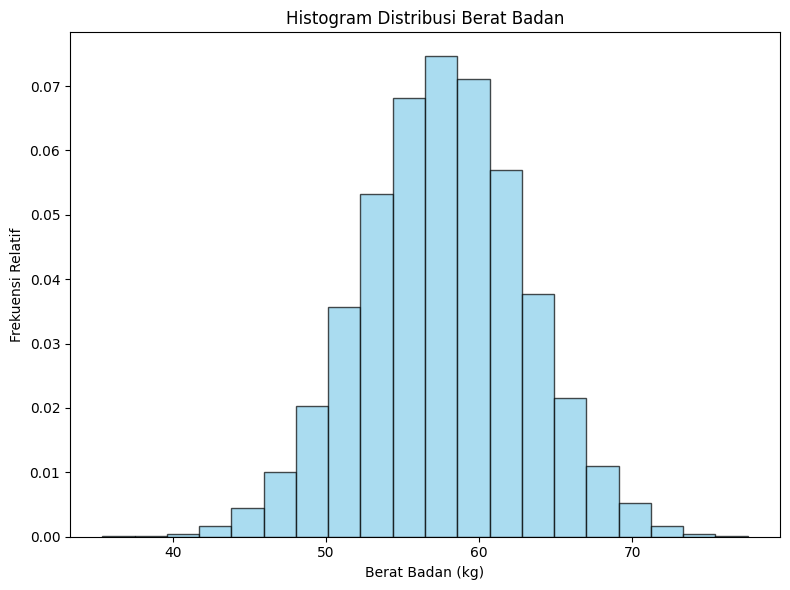

In [29]:
# Histogram
plt.figure(figsize=(8, 6))
plt.hist(df['Weight(Kilograms)'], bins=20, color='skyblue', edgecolor='black', alpha=0.7, density=True)
plt.title('Histogram Distribusi Berat Badan')
plt.xlabel('Berat Badan (kg)')
plt.ylabel('Frekuensi Relatif')
plt.tight_layout()
plt.show()

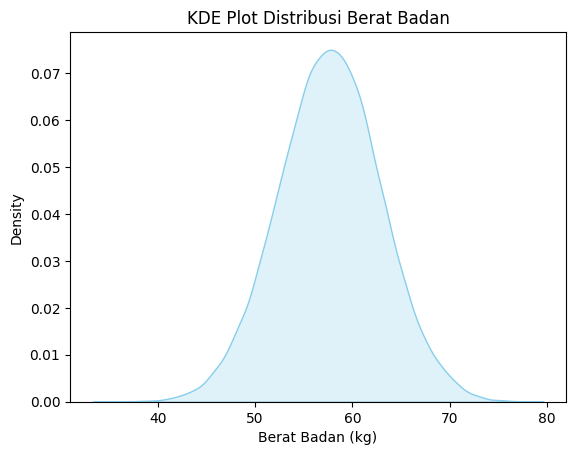

In [30]:
# KDE Plot
sns.kdeplot(df['Weight(Kilograms)'], fill=True, color='skyblue')
plt.title('KDE Plot Distribusi Berat Badan')
plt.xlabel('Berat Badan (kg)')
plt.show()

[Text(0.5, 1.0, 'Boxplot')]

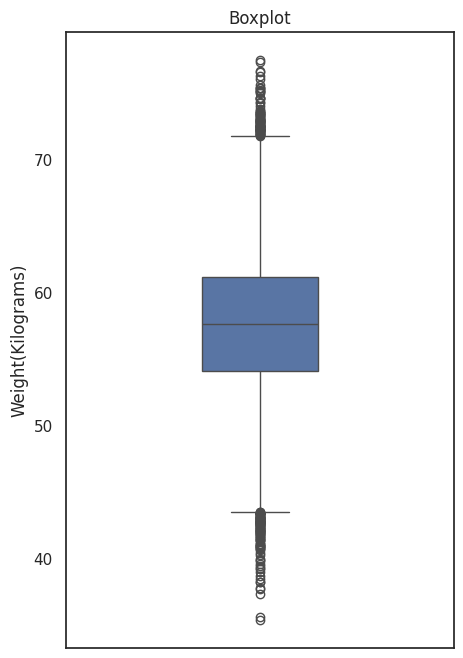

In [31]:
#Boxplot
sns.set(style='white', rc={'figure.figsize':(5, 8)})
sns.boxplot(df['Weight(Kilograms)'], width=0.3).set(title='Boxplot')

In [32]:
# Hipotesis:
# H0: Sampel berat badan manusia berdistribusi Normal.
# H1: Sampel berat badan manusia tidak berdistribusi Normal.

# Taraf signifikansi:
# Gunakan alpha = 5%.

# Uji statistik:
# Penelitian ini menggunakan statistik uji Shapiro-Wilk, D’Agostino dan Pearson, Chi- square, dan Jarque-Bera.

# Kriteria penolakan:
# H0 ditolak jika nilai P value < alpha

stat, p = shapiro(df['Weight(Kilograms)'])
print('Statistik = %.3f, P value = %.3f' %(stat, p))
if p > 0.05:
  print('Sampel berat badan manusia Berdistribusi Normal (H0)')
else:
  print('Sampel berat badan manusia Tidak berdistribusi Normal (H1)')

stat, p = normaltest(df['Weight(Kilograms)'])
print('\nStatistik = %.3f, P value = %.3f' %(stat, p))
if p > 0.05:
  print('Sampel berat badan manusia Berdistribusi Normal (H0)')
else:
  print('Sampel berat badan manusia Tidak berdistribusi Normal (H1)')

stat, p = jarque_bera(df['Weight(Kilograms)'])
print('\nStatistik = %.3f, P value = %.3f' %(stat, p))
if p > 0.05:
  print('Sampel berat badan manusia Berdistribusi Normal (H0)')
else:
  print('Sampel berat badan manusia Tidak berdistribusi Normal (H1)')

stat, p = chisquare(df['Weight(Kilograms)'])
print('\nStatistik = %.3f, P value = %.3f' %(stat, p))
if p > 0.05:
  print('Sampel berat badan manusia Berdistribusi Normal (H0)')
else:
  print('Sampel berat badan manusia Tidak berdistribusi Normal (H1)')

Statistik = 1.000, P value = 0.396
Sampel berat badan manusia Berdistribusi Normal (H0)

Statistik = 4.865, P value = 0.088
Sampel berat badan manusia Berdistribusi Normal (H0)

Statistik = 4.885, P value = 0.087
Sampel berat badan manusia Berdistribusi Normal (H0)

Statistik = 12133.239, P value = 1.000
Sampel berat badan manusia Berdistribusi Normal (H0)


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 25000.
  res = hypotest_fun_out(*samples, **kwds)


In [33]:
mu_0=60
t_statistic, p_value = stats.ttest_1samp(a=df['Weight(Kilograms)'], popmean=mu_0)
print('t hitung = %.3f, P value = %.3f' %(t_statistic , p_value))
if p_value < 0.05:
  print('Secara signifikansi, rata-rata sampel bukan', mu_0)
elif p_value >= 0.05:
  print('Secara signifikansi, rata-rata sampel adalah', mu_0)

t hitung = -70.482, P value = 0.000
Secara signifikansi, rata-rata sampel bukan 60


# **BAB III UJI *t* SALING BEBAS**

In [34]:
# Pisahkan data berdasarkan gender
male = df[df['Gender'] == 'Male']['Weight(Kilograms)'].dropna()
female = df[df['Gender'] == 'Female']['Weight(Kilograms)'].dropna()

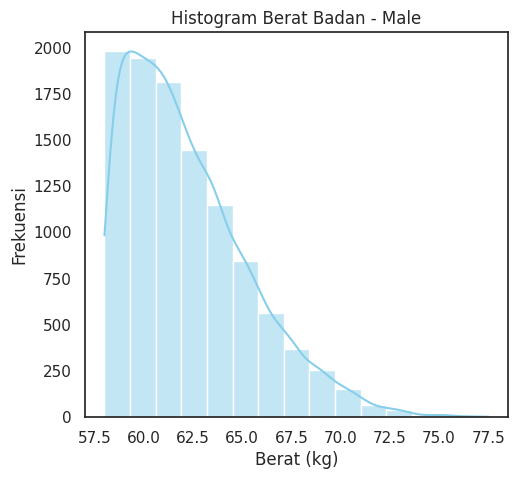

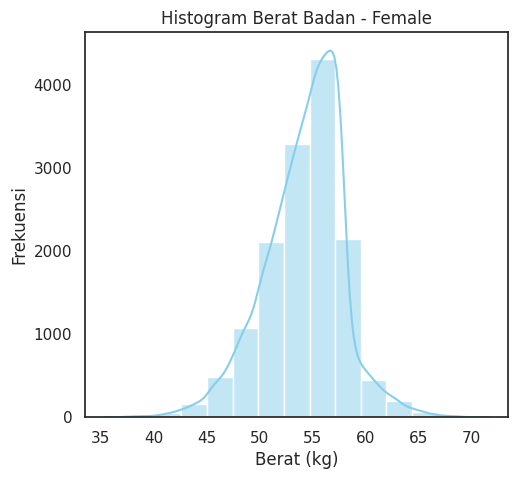

In [35]:
# Histogram
def visualisasi_normalitas(data, label):
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    sns.histplot(data, kde=True, bins=15, color='skyblue')
    plt.title(f'Histogram Berat Badan - {label}')
    plt.xlabel('Berat (kg)')
    plt.ylabel('Frekuensi')

visualisasi_normalitas(male, "Male")
visualisasi_normalitas(female, "Female")

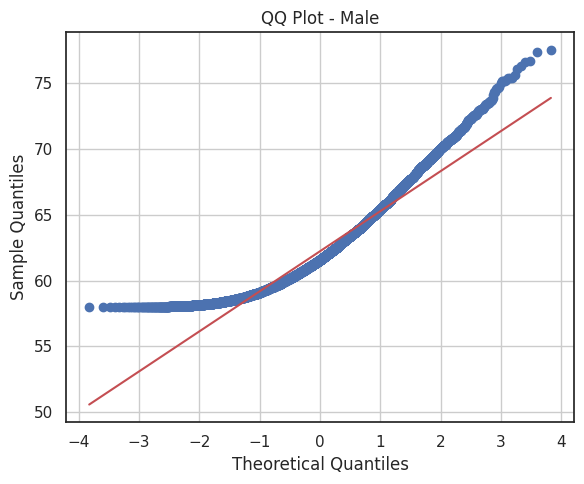

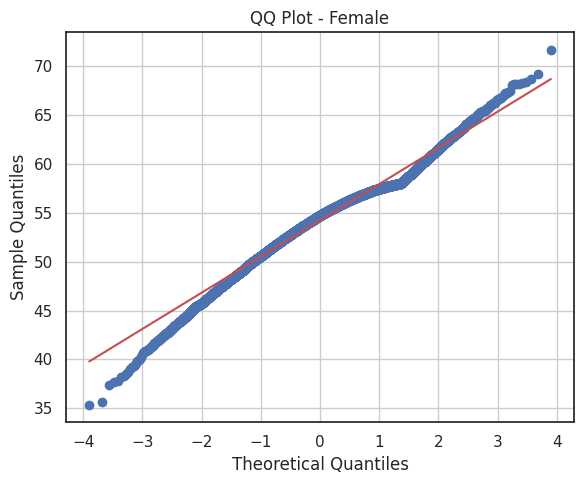

In [36]:
# QQ Plot
def qq_plot(data, label):
    plt.figure(figsize=(6, 5))
    stats.probplot(data, dist="norm", plot=plt)
    plt.title(f'QQ Plot - {label}')
    plt.xlabel('Theoretical Quantiles')
    plt.ylabel('Sample Quantiles')
    plt.grid(True)
    plt.tight_layout()
    plt.show()
qq_plot(male, "Male")
qq_plot(female, "Female")

/tmp/ipykernel_1094/3991432055.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Gender', y='Weight(Kilograms)', data=df, palette='pastel')


Text(0.5, 1.0, 'Distribusi Berat Badan per Gender')

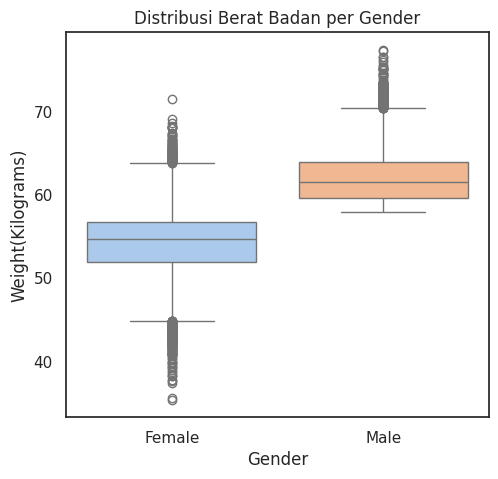

In [37]:
# Boxplot
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.boxplot(x='Gender', y='Weight(Kilograms)', data=df, palette='pastel')
plt.title('Distribusi Berat Badan per Gender')

In [38]:
# Uji Normalitas (Shapiro-Wilk)
# Hipotesis 1:
# H0: Sampel berat badan kelompok laki-laki Berdistribusi Normal.
# H1: Sampel berat badan kelompok laki-laki Tidak Berdistribusi Normal.

# Hipotesis 2:
# Sampel berat badan kelompok perempuan Berdistribusi Normal.
# Sampel berat badan kelompok perempuan Tidak Berdistribusi Normal.

# Taraf signifikansi:
# Gunakan alpha = 5%.

# Uji statistik:
# Penelitian ini menggunakan statistik uji Shapiro-Wilk.

# Kriteria penolakan:
# H0 ditolak jika nilai P value < alpha

stat, p = shapiro(male)
print('Statistik = %.3f, P value = %.3f' %(stat, p))
if p > 0.05:
  print('Sampel berat badan kelompok laki-laki Berdistribusi Normal (H0)')
else:
  print('Sampel berat badan kelompok laki-laki Tidak berdistribusi Normal (H1)')

stat, p = shapiro(female)
print('\nStatistik = %.3f, P value = %.3f' %(stat, p))
if p > 0.05:
  print('Sampel berat badan kelompok perempuan Berdistribusi Normal (H0)')
else:
  print('Sampel berat badan kelompok perempuan Tidak berdistribusi Normal (H1)')

Statistik = 0.929, P value = 0.000
Sampel berat badan kelompok laki-laki Tidak berdistribusi Normal (H1)

Statistik = 0.979, P value = 0.000
Sampel berat badan kelompok perempuan Tidak berdistribusi Normal (H1)


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 10651.
  res = hypotest_fun_out(*samples, **kwds)
/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 14349.
  res = hypotest_fun_out(*samples, **kwds)


In [39]:
# Uji homogenitas varians
# H₀ : Varians kedua kelompok sama (homogen).
# H₁ : Varians kedua kelompok berbeda (tidak homogen).
stat_levene, p_levene = levene(male, female)
print("Uji Levene")
print(f"Statistik = {stat_levene:.3f}, p = {p_levene:.3f}")
if p_levene > 0.05:
    print("Variansi antar kelompok homogen (setara) (H0)")
else:
    print("Variansi antar kelompok tidak homogen (berbeda) (H1)")

Uji Levene
Statistik = 183.924, p = 0.000
Variansi antar kelompok tidak homogen (berbeda) (H1)


In [40]:
# Uji Mann-Whitney U
stat_mw, p_mw = mannwhitneyu(male, female, alternative='two-sided')
print(f"Mann-Whitney U Test: Statistik = {stat_mw:.3f}, p = {p_mw:.3f}")

alpha = 0.05
if p_mw < alpha:
    print("H1: Rata-rata data sampel pertama tidak sama dengan rata-rata data sampel kedua (p < 0.05)")
else:
    print("H0 : Rata-rata data sampel pertama sama dengan rata-rata data sampel kedua (p > 0.05)")

Mann-Whitney U Test: Statistik = 148472076.000, p = 0.000
H1: Rata-rata data sampel pertama tidak sama dengan rata-rata data sampel kedua (p < 0.05)


# **BAB IV UJI *t* BERPASANGAN**

In [41]:
print(df2.head())

           Date  Before breakfast  Before lunch  2h after lunch  \
0   Wed. 9/Feb.        116.156923           157      132.504762   
1  Thu. 10/Feb.        105.000000           155      132.504762   
2  Fri. 11/Feb.        101.000000           138      132.504762   
3  Sat. 12/Feb.         98.000000           123      132.504762   
4  Sun. 13/Feb.        107.000000           157      132.504762   

   Before dinner  2h after dinner  
0            163          165.000  
1            163          197.875  
2            130          170.735  
3            163          138.875  
4            163          138.875  


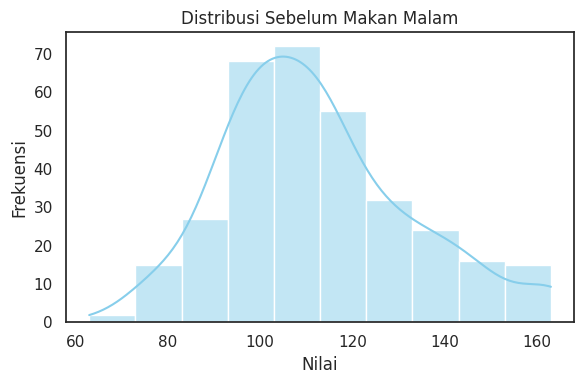

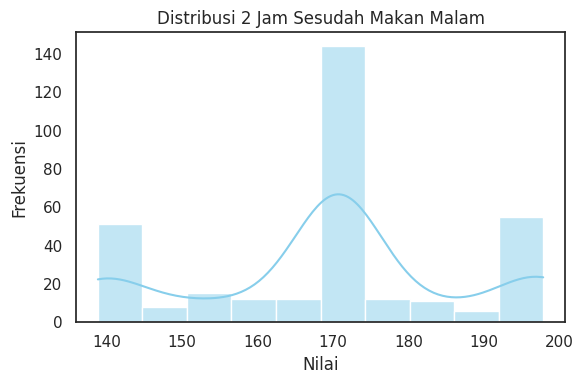

In [42]:
# Histogram
plt.figure(figsize=(6,4))
sns.histplot(df2['Before dinner'], bins=10, kde=True, color='skyblue')
plt.title("Distribusi Sebelum Makan Malam")
plt.xlabel("Nilai")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6,4))
sns.histplot(df2['2h after dinner'], bins=10, kde=True, color='skyblue')
plt.title("Distribusi 2 Jam Sesudah Makan Malam")
plt.xlabel("Nilai")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

/tmp/ipykernel_1094/3017906831.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Kondisi', y='Nilai', data=df_long, palette='Set2')


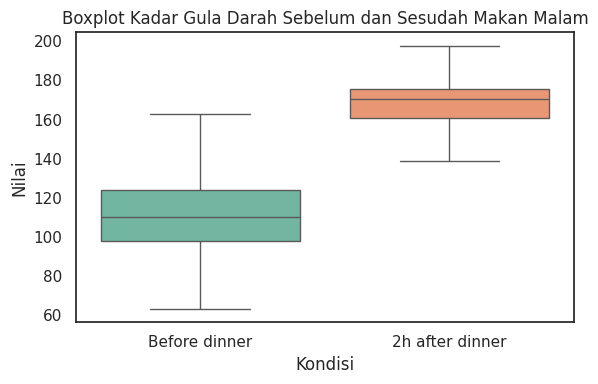

In [43]:
# Boxplot
df_long = pd.melt(df2, value_vars=['Before dinner', '2h after dinner'], var_name='Kondisi', value_name='Nilai')
plt.figure(figsize=(6, 4))
sns.boxplot(x='Kondisi', y='Nilai', data=df_long, palette='Set2')
plt.title("Boxplot Kadar Gula Darah Sebelum dan Sesudah Makan Malam")
plt.ylabel("Nilai")
plt.xlabel("Kondisi")
plt.tight_layout()
plt.show()

/tmp/ipykernel_1094/3377988286.py:5: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(selisih1, shade=True, ax=axes[0], color='steelblue')
/tmp/ipykernel_1094/3377988286.py:9: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(selisih2, shade=True, ax=axes[1], color='darkorange')


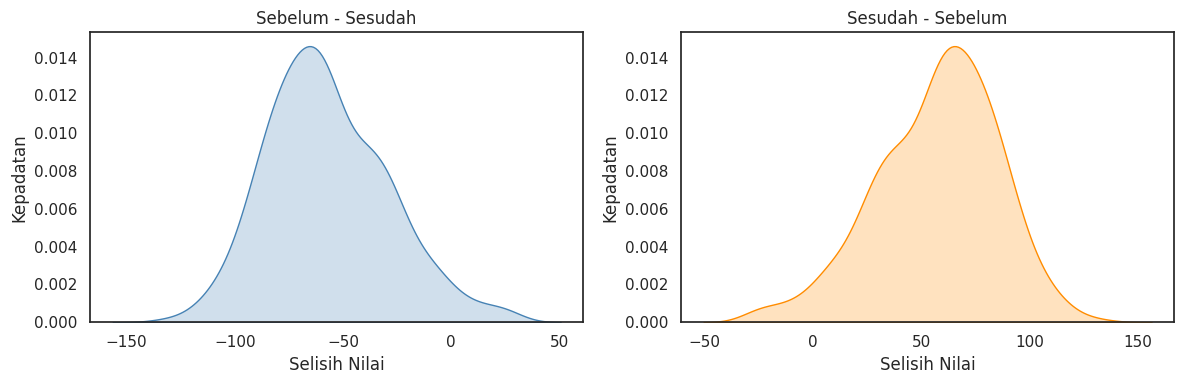

In [44]:
# Hitung selisih dua arah
selisih1 = df2['Before dinner'] - df2['2h after dinner']
selisih2 = df2['2h after dinner'] - df2['Before dinner']
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.kdeplot(selisih1, shade=True, ax=axes[0], color='steelblue')
axes[0].set_title("Sebelum - Sesudah", fontsize=12)
axes[0].set_xlabel("Selisih Nilai")
axes[0].set_ylabel("Kepadatan")
sns.kdeplot(selisih2, shade=True, ax=axes[1], color='darkorange')
axes[1].set_title("Sesudah - Sebelum", fontsize=12)
axes[1].set_xlabel("Selisih Nilai")
axes[1].set_ylabel("Kepadatan")
plt.tight_layout()
plt.show()

In [45]:
# Uji normalitas dengan Shapiro-Wilk
# Hipotesis:
# H0: Sampel sebelum - sesudah makan malam Berdistribusi Normal.
# H1: Sampel sesudah - sebelum makan malam Tidak Berdistribusi Normal.

# Taraf signifikansi:
# Gunakan alpha = 5%.

# Uji statistik:
# Penelitian ini menggunakan statistik uji Shapiro-Wilk.

# Kriteria penolakan:
# H0 ditolak jika nilai P value < alpha

stat, p = shapiro(selisih1)
print('Selisih Sebelum - Sesudah')
print('Statistik = %.3f, P value = %.3f' %(stat, p))
if p > 0.05:
  print('Berdistribusi Normal (H0)')
else:
  print('Tidak berdistribusi Normal (H1)')

stat, p = shapiro(selisih2)
print('\nSelisih Sesudah - Sebelum')
print('Statistik = %.3f, P value = %.3f' %(stat, p))
if p > 0.05:
  print('Berdistribusi Normal (H0)')
else:
  print('Tidak berdistribusi Normal (H1)')

Selisih Sebelum - Sesudah
Statistik = 0.984, P value = 0.001
Tidak berdistribusi Normal (H1)

Selisih Sesudah - Sebelum
Statistik = 0.984, P value = 0.001
Tidak berdistribusi Normal (H1)


In [46]:
# Statistik deskriptif
print("Statistik Deskriptif Sebelum - Sesudah:")
print(selisih1.describe())

print("\nStatistik Deskriptif Sesudah - Sebelum:")
print(selisih2.describe())

Statistik Deskriptif Sebelum - Sesudah:
count    326.000000
mean     -57.256472
std       27.958581
min     -130.000000
25%      -77.735000
50%      -60.735000
75%      -38.875000
max       24.125000
dtype: float64

Statistik Deskriptif Sesudah - Sebelum:
count    326.000000
mean      57.256472
std       27.958581
min      -24.125000
25%       38.875000
50%       60.735000
75%       77.735000
max      130.000000
dtype: float64


In [47]:
before = df2["Before dinner"]
after = df2["2h after dinner"]
# Hipotesis:
# H0: Median kadar gula darah sebelum dan sesudah sama (tidak ada perubahan)
# H1: Median kadar gula darah sebelum dan sesudah berbeda (ada perubahan)
stat, p = wilcoxon(before, after)
print(f"Uji Wilcoxon \nStatistik = {stat:.4f}, p-value = {p:.4f}")

alpha = 0.05
if p < alpha:
    print("Terdapat perbedaan signifikan antara kadar gula darah sebelum dan sesudah (H1).")
else:
    print("Tidak terdapat perbedaan signifikan antara kadar gula darah sebelum dan sesudah (H0).")

Uji Wilcoxon 
Statistik = 223.5000, p-value = 0.0000
Terdapat perbedaan signifikan antara kadar gula darah sebelum dan sesudah (H1).


# **BAB V ANALISIS VARIANSI (ANAVA) 1 ARAH**

In [48]:
print(df3.head())

   sepal_length  sepal_width  petal_length  petal_width      species
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa


/tmp/ipykernel_1094/1510092276.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title="Species")


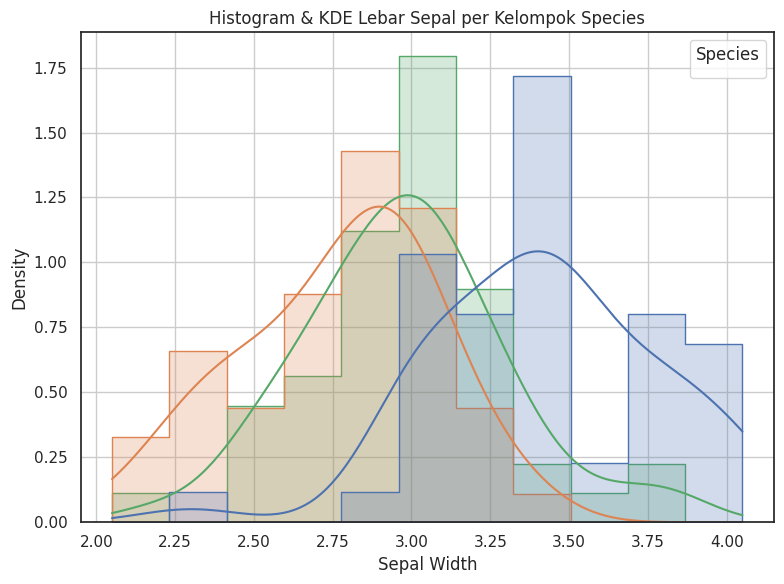

In [49]:
# Histogram dan KDE
plt.figure(figsize=(8, 6))
sns.histplot(data=df3, x="sepal_width", hue="species", kde=True, element="step", stat="density", common_norm=False)
plt.title("Histogram & KDE Lebar Sepal per Kelompok Species")
plt.xlabel("Sepal Width")
plt.ylabel("Density")
plt.legend(title="Species")
plt.grid(True)
plt.tight_layout()
plt.show()

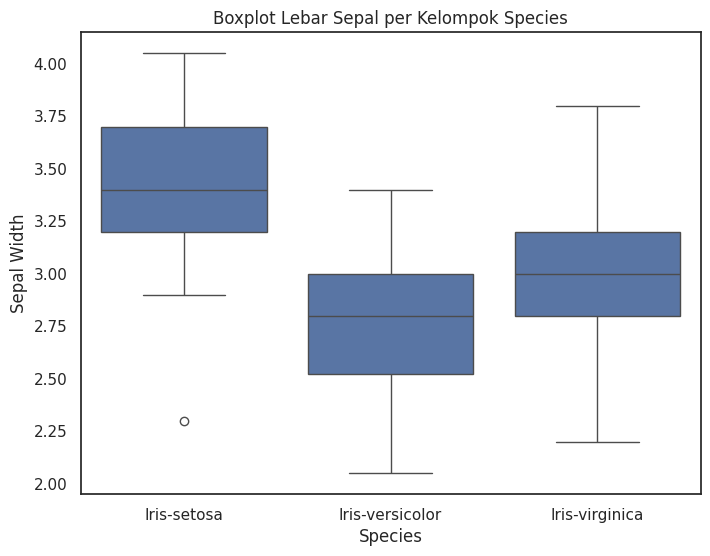

In [50]:
# Boxplot
plt.figure(figsize=(8,6))
sns.boxplot(x='species', y='sepal_width', data=df3)
plt.title('Boxplot Lebar Sepal per Kelompok Species')
plt.xlabel('Species')
plt.ylabel('Sepal Width')
plt.show()

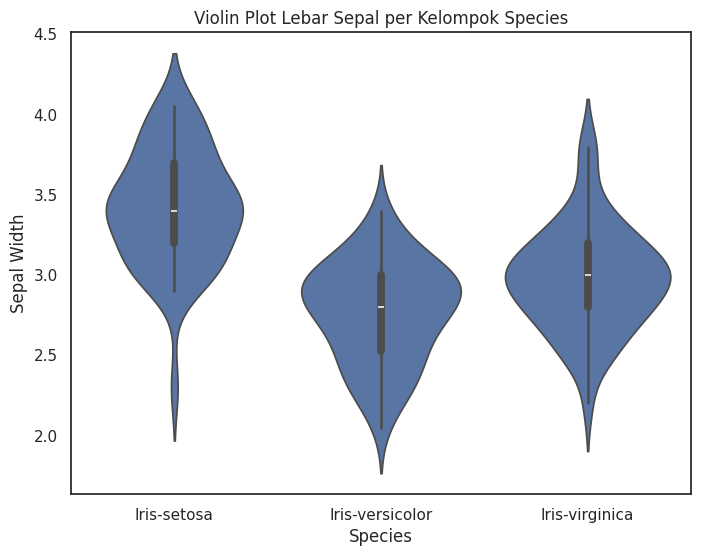

In [51]:
# Violin plot
plt.figure(figsize=(8,6))
sns.violinplot(x='species', y='sepal_width', data=df3)
plt.title('Violin Plot Lebar Sepal per Kelompok Species')
plt.xlabel('Species')
plt.ylabel('Sepal Width')
plt.show()

In [52]:
# Uji normalitas Shapiro-Wilk tiap kelompok
# Hipotesis:
# H0: Sampel tiap kelompok spesies Berdistribusi Normal.
# H1: Sampel tiap kelompok spesies Tidak Berdistribusi Normal.

# Taraf signifikansi:
# Gunakan alpha = 5%.

# Uji statistik:
# Penelitian ini menggunakan statistik uji Shapiro-Wilk.

# Kriteria penolakan:
# H0 ditolak jika nilai P value < alpha

print("Uji Normalitas (Shapiro-Wilk):")
for species, group_data in df3.groupby('species'):
    stat, p = shapiro(group_data['sepal_width'])
    print(f'{species}: Statistik = %.3f, P value = %.3f' %(stat, p))
    if p > 0.05:
      print('Berdistribusi Normal (H0)')
    else:
      print('Tidak berdistribusi Normal (H1)')

Uji Normalitas (Shapiro-Wilk):
Iris-setosa: Statistik = 0.959, P value = 0.096
Berdistribusi Normal (H0)
Iris-versicolor: Statistik = 0.973, P value = 0.319
Berdistribusi Normal (H0)
Iris-virginica: Statistik = 0.967, P value = 0.187
Berdistribusi Normal (H0)


In [53]:
# Uji Hartley untuk homogenitas varians
# H0 : Varians antar kelompok spesies sama (homogen).
# H1 : Varians antar kelompok spesies berbeda (tidak homogen).
grouped = df3.groupby("species")["sepal_width"]
# Hitung variansi masing-masing kelompok
variances = [np.var(group, ddof=1) for name, group in grouped]
# Hitung rasio F-max (variansi terbesar / terkecil)
f_max = max(variances) / min(variances)
print("Uji Hartley (F-max)")
print("Variansi per kelompok:", variances)
print(f"F-max = {f_max:.3f}")
if f_max < 2:
    print("H0: Variansi antar kelompok dianggap homogen (F-max < 2)")
else:
    print("H1: Variansi antar kelompok kemungkinan tidak homogen (F-max > 2)")
    print("Asumsi homogenitas mungkin tidak terpenuhi")

Uji Hartley (F-max)
Variansi per kelompok: [0.12912123226950353, 0.09694795918367356, 0.1045748299319728]
F-max = 1.332
H0: Variansi antar kelompok dianggap homogen (F-max < 2)


In [54]:
# Uji Bartlett untuk homogenitas varians
# H0 : Varians antar kelompok spesies sama (homogen).
# H1 : Varians antar kelompok spesies berbeda (tidak homogen).
grouped = [group["sepal_width"].values for name, group in df3.groupby("species")]
stat, p = bartlett(*grouped)
print("Uji Bartlett")
print(f"Statistik Bartlett = {stat:.3f}")
print(f"P-value = {p:.3f}")
if p > 0.05:
    print("H0: Variansi antar kelompok homogen (setara)")
else:
    print("H1: Variansi antar kelompok tidak homogen (berbeda)")

Uji Bartlett
Statistik Bartlett = 1.063
P-value = 0.588
H0: Variansi antar kelompok homogen (setara)


In [55]:
# Uji Levene untuk homogenitas varians
# H0 : Varians antar kelompok spesies sama (homogen).
# H1 : Varians antar kelompok spesies berbeda (tidak homogen).
groups = [group['sepal_width'].values for name, group in df3.groupby('species')]
stat_levene, p_levene = levene(*groups)
print("Uji Levene")
print(f"Statistik = {stat_levene:.3f}, p = {p_levene:.3f}")
if p_levene > 0.05:
    print("H0: Variansi antar kelompok homogen (setara)")
else:
    print("H1: Variansi antar kelompok tidak homogen (berbeda)")

Uji Levene
Statistik = 0.388, p = 0.679
H0: Variansi antar kelompok homogen (setara)


In [56]:
# Uji ANAVA Satu Arah
group_data = [group['sepal_width'].values for name, group in df3.groupby('species')]
f_stat, p_value = f_oneway(*group_data)
print("Hasil Uji ANAVA Satu Arah:")
print(f"F-statistik = {f_stat:.3f}, P value = {p_value:.3f}")
alpha = 0.05
if p_value < alpha:
    print("H1: Terdapat perbedaan rata-rata sepal_width yang signifikan antara spesies.")
else:
    print("H0: Tidak terdapat perbedaan signifikan antara rata-rata sepal_width antar spesies.")

Hasil Uji ANAVA Satu Arah:
F-statistik = 48.631, P value = 0.000
H1: Terdapat perbedaan rata-rata sepal_width yang signifikan antara spesies.


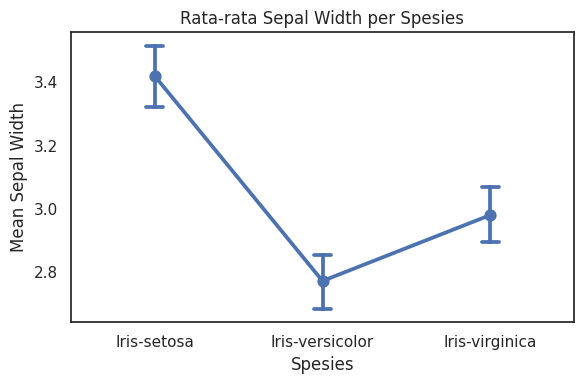

In [57]:
plt.figure(figsize=(6, 4))
sns.pointplot(data=df3, x='species', y='sepal_width', capsize=0.1)
plt.title('Rata-rata Sepal Width per Spesies')
plt.xlabel('Spesies')
plt.ylabel('Mean Sepal Width')
plt.tight_layout()
plt.show()

# **BAB VI ANALISIS VARIANSI (ANAVA) 2 ARAH**

In [58]:
print(df5.head())

         Date  Product Name     Category  Units Sold  Price  Revenue  \
0  2020-01-06  Whey Protein      Protein         143  31.98  4573.14   
1  2020-01-06     Vitamin C      Vitamin         139  42.51  5908.89   
2  2020-01-06      Fish Oil        Omega         161  12.91  2078.51   
3  2020-01-06  Multivitamin      Vitamin         140  16.07  2249.80   
4  2020-01-06   Pre-Workout  Performance         157  35.47  5568.79   

   Discount  Units Returned Location Platform  
0      0.03               2   Canada  Walmart  
1      0.04               0       UK   Amazon  
2      0.25               0   Canada   Amazon  
3      0.08               0   Canada  Walmart  
4      0.25               3   Canada    iHerb  


In [59]:
model_1 = ols('Q("Units Sold") ~ (Location) * (Platform)', data=df5).fit()
residual_1 = model_1.resid

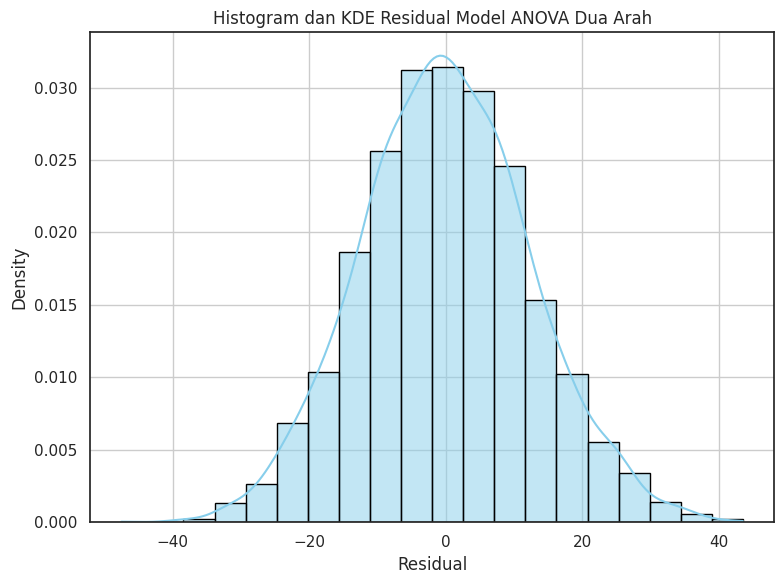

In [60]:
# Histogram
residual_1 = model_1.resid
plt.figure(figsize=(8, 6))
sns.histplot(residual_1, kde=True, stat="density", bins=20, color="skyblue", edgecolor="black")
plt.title("Histogram dan KDE Residual Model ANOVA Dua Arah")
plt.xlabel("Residual")
plt.ylabel("Density")
plt.grid(True)
plt.tight_layout()
plt.show()

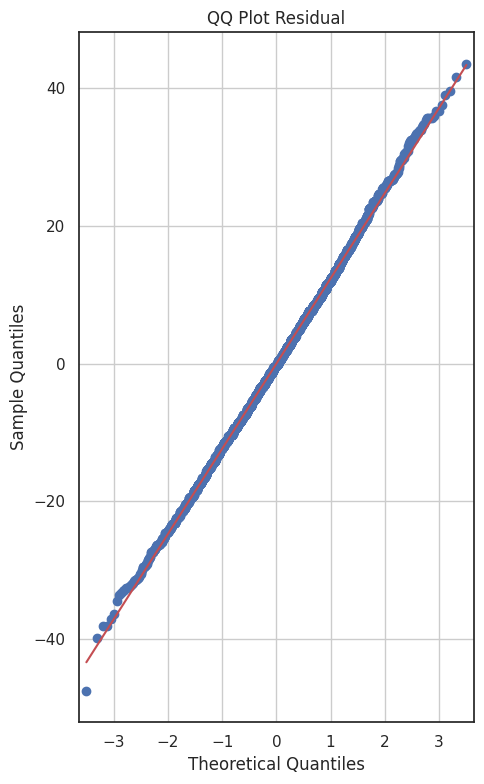

In [61]:
# QQ plot
sm.qqplot(model_1.resid, line='s')
plt.title("QQ Plot Residual")
plt.grid(True)
plt.tight_layout()
plt.show()

In [62]:
# Hipotesis:
# H0: Residual model regresi lokasi dan platform Berdistribusi Normal.
# H1: Residual model regresi lokasi dan platform Tidak berdistribusi Normal.

# Taraf signifikansi:
# Gunakan alpha = 5%.

# Uji statistik:
# Penelitian ini menggunakan statistik uji Shapiro-Wilk, D’Agostino dan Pearson, Chi- square, dan Jarque-Bera.

# Kriteria penolakan:
# H0 ditolak jika nilai P value < alpha

stat, p = shapiro(residual_1)
print('Statistik = %.3f, P value = %.3f' %(stat, p))
if p > 0.05:
  print('H0: Residual Berdistribusi Normal')
else:
  print('H1: Residual Tidak berdistribusi Normal')

stat, p = normaltest(residual_1)
print('Statistik = %.3f, P value = %.3f' %(stat, p))
if p > 0.05:
  print('H0: Residual Berdistribusi Normal')
else:
  print('H1: Residual Tidak berdistribusi Normal')

stat, p = jarque_bera(residual_1)
print('Statistik = %.3f, P value = %.3f' %(stat, p))
if p > 0.05:
  print('H0: Residual Berdistribusi Normal')
else:
  print('H1: Residual Tidak berdistribusi Normal')

stat, p = chisquare(residual_1)
print('Statistik = %.3f, P value = %.3f' %(stat, p))
if p > 0.05:
  print('H0: Residual Berdistribusi Normal')
else:
  print('H1: Residual Tidak berdistribusi Normal')

Statistik = 0.999, P value = 0.096
H0: Residual Berdistribusi Normal
Statistik = 4.589, P value = 0.101
H0: Residual Berdistribusi Normal
Statistik = 4.573, P value = 0.102
H0: Residual Berdistribusi Normal
Statistik = -4204871429800484864.000, P value = nan
H1: Residual Tidak berdistribusi Normal


In [63]:
# Uji Hartley untuk homogenitas varians
# H0 : Varians antar kelompok lokasi dan platform sama (homogen).
# H1 : Varians antar kelompok lokasi dan platform berbeda (tidak homogen).
grouped = df5.groupby(['Location', 'Platform'])['Units Sold']
# Hitung variansi masing-masing kelompok
variances = [np.var(group, ddof=1) for name, group in grouped]
# Hitung rasio F-max (variansi terbesar / terkecil)
f_max = max(variances) / min(variances)
print("Uji Hartley (F-max)")
print("Variansi per kelompok:", variances)
print(f"F-max = {f_max:.3f}")
if f_max < 2:
    print("H0: Variansi antar kelompok dianggap homogen (F-max < 2)")
else:
    print("H1: Variansi antar kelompok kemungkinan tidak homogen (F-max > 2)")
    print("Asumsi homogenitas mungkin tidak terpenuhi")

Uji Hartley (F-max)
Variansi per kelompok: [155.94855089820337, 164.8583810614737, 157.52298799466425, 143.1973665973667, 154.86488622754493, 148.33283860221977, 144.34297352342173, 164.18504994450603, 149.64232743625644]
F-max = 1.151
H0: Variansi antar kelompok dianggap homogen (F-max < 2)


In [64]:
# Uji Levene untuk homogenitas varians
# H0 : Varians antar kelompok lokasi dan platform sama (homogen).
# H1 : Varians antar kelompok lokasi dan platform berbeda (tidak homogen).
groups = [group['Units Sold'].values for _, group in df5.groupby(['Location', 'Platform'])]
stat_levene, p_levene = levene(*groups)
print("Uji Levene")
print(f"Statistik = {stat_levene:.3f}, p = {p_levene:.3f}")
if p_levene > 0.05:
    print("H0: Variansi antar kelompok homogen (setara)")
else:
    print("H1: Variansi antar kelompok tidak homogen (berbeda)")

Uji Levene
Statistik = 0.806, p = 0.597
H0: Variansi antar kelompok homogen (setara)


In [65]:
# Uji Autokorelasi (Breusch-Godfrey)
# H0 : Tidak ada autokorelasi residual model regresi lokasi dan platform.
# H1 : Ada autokorelasi residual model regresi lokasi dan platform.
bg_test = acorr_breusch_godfrey(model_1, nlags=1)
bg_stat = bg_test[0]
bg_pvalue = bg_test[1]
print(f'Breusch-Godfrey Statistic: {bg_stat:.3f}')
print(f'Breusch-Godfrey p-value: {bg_pvalue:.3f}')
if bg_pvalue > 0.05:
    print('H0: Tidak ada autokorelasi residual (asumsi independensi terpenuhi)')
else:
    print('H1: Terdapat autokorelasi residual (asumsi independensi dilanggar)')

Breusch-Godfrey Statistic: 0.338
Breusch-Godfrey p-value: 0.561
H0: Tidak ada autokorelasi residual (asumsi independensi terpenuhi)


/tmp/ipykernel_1094/3523180316.py:4: FutureWarning: acorr_breusch_godfrey currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  bg_test = acorr_breusch_godfrey(model_1, nlags=1)


In [66]:
# ANAVA 2 Arah
anova_result = anova_lm(model_1, typ=2)
print("ANOVA Dua Arah:")
print(anova_result)
for factor in anova_result.index:
    p_value = anova_result.loc[factor, 'PR(>F)']
    if p_value < 0.05:
        print(f"\nHipotesis untuk '{factor}': Ditolak H0")
        if factor == 'Location':
            print("- Ada perbedaan signifikan rata-rata unit terjual antar lokasi.")
        elif factor == 'Platform':
            print("- Ada perbedaan signifikan rata-rata unit terjual antar Platform.")
        else:
            print("- Ada interaksi signifikan antara lokasi dan platform terhadap unit terjual.")
    else:
        print(f"\nHipotesis untuk '{factor}': Gagal tolak H0")
        if factor == 'Location':
            print("- Tidak ada perbedaan signifikan rata-rata unit terjual antar lokasi.")
        elif factor == 'Platform':
            print("- Tidak ada perbedaan signifikan rata-rata unit terjual antar platform.")
        else:
            print("- Tidak ada interaksi signifikan antara lokasi dan platform terhadap unit terjual.")

ANOVA Dua Arah:
                          sum_sq      df         F    PR(>F)
Location              404.792844     2.0  1.318173  0.267730
Platform              416.232253     2.0  1.355425  0.257946
Location:Platform     952.201257     4.0  1.550381  0.184803
Residual           671751.003715  4375.0       NaN       NaN

Hipotesis untuk 'Location': Gagal tolak H0
- Tidak ada perbedaan signifikan rata-rata unit terjual antar lokasi.

Hipotesis untuk 'Platform': Gagal tolak H0
- Tidak ada perbedaan signifikan rata-rata unit terjual antar platform.

Hipotesis untuk 'Location:Platform': Gagal tolak H0
- Tidak ada interaksi signifikan antara lokasi dan platform terhadap unit terjual.

Hipotesis untuk 'Residual': Gagal tolak H0
- Tidak ada interaksi signifikan antara lokasi dan platform terhadap unit terjual.


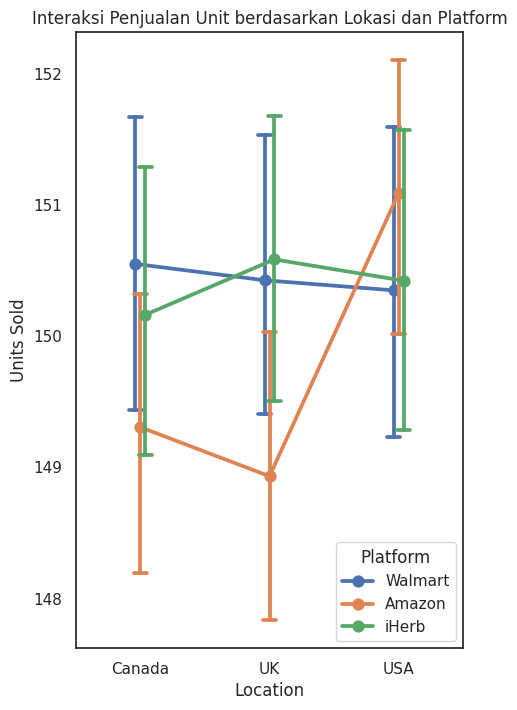

In [67]:
# Visual Interaksi
sns.pointplot(data=df5, x='Location', y='Units Sold', hue='Platform', dodge=True, capsize=.1)
plt.title('Interaksi Penjualan Unit berdasarkan Lokasi dan Platform')
plt.show()

# **BAB VII ANALISIS KORELASI**

In [68]:
print("\nCek missing value:")
print(df.isnull().sum())


Cek missing value:
Height(Centimeter)    0
Weight(Kilograms)     0
Gender                0
BMI                   0
Skin Color            0
Clothes Color         0
Pants Color           0
dtype: int64


In [69]:
results = []

cols = df.select_dtypes(include=['float64', 'int64'])

for col in cols:
  q1 = df[col].quantile(0.25)
  q3 = df[col].quantile(0.75)
  iqr = q3 - q1
  lower_bound = q1 - 1.5*iqr
  upper_bound = q3 + 1.5*iqr
  outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
  percent_outliers = (len(outliers)/len(df))*100
  results.append({'Kolom': col, 'Persentase Outliers': percent_outliers})

# Dataframe dari list hasil
results_df = pd.DataFrame(results)
results_df.set_index('Kolom', inplace=True)
results_df = results_df.rename_axis(None, axis=0).rename_axis('Kolom', axis=1)

# Tampilkan dataframe
display(results_df)

Kolom,Persentase Outliers
Height(Centimeter),0.668
Weight(Kilograms),0.764


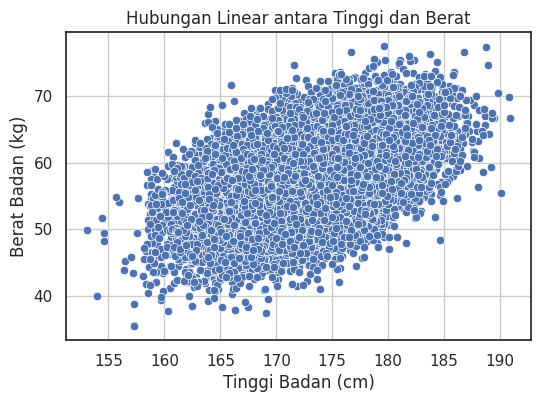

In [70]:
plt.figure(figsize=(6,4))
sns.scatterplot(x='Height(Centimeter)', y='Weight(Kilograms)', data=df)
plt.title('Hubungan Linear antara Tinggi dan Berat')
plt.xlabel('Tinggi Badan (cm)')
plt.ylabel('Berat Badan (kg)')
plt.grid(True)
plt.show()

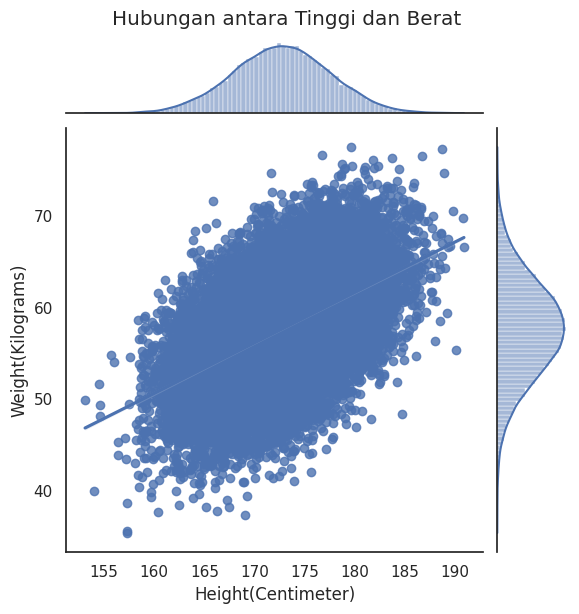

In [71]:
sns.jointplot(data=df, x='Height(Centimeter)', y='Weight(Kilograms)', kind='reg', height=6)
plt.suptitle('Hubungan antara Tinggi dan Berat', y=1.02)
plt.show()

In [72]:
# Variabel yang dianalisis korelasinya:
data1 = 'Height(Centimeter)'
data2 = 'Weight(Kilograms)'
# Uji Normalitas untuk kedua variabel
# Hipotesis:
# H0: Sampel tinggi badan manusia Berdistribusi Normal.
# H1: Sampel berat badan manusia Tidak berdistribusi Normal.
stat1, p1 = shapiro(df[data1])
stat2, p2 = shapiro(df[data2])
print(f'Statistik {data1}: p-value = {p1:.4f}')
if p1 > 0.05:
  print('H0: Sampel tinggi badan manusia Berdistribusi Normal.')
else:
  print('H1: Sampel berat badan manusia Tidak berdistribusi Normal.')
print(f'\nStatistik {data2}: p-value = {p2:.4f}')
if p2 > 0.05:
  print('H0: Sampel tinggi badan manusia Berdistribusi Normal.')
else:
  print('H1: Sampel berat badan manusia Tidak berdistribusi Normal.')

Statistik Height(Centimeter): p-value = 0.6627
H0: Sampel tinggi badan manusia Berdistribusi Normal.

Statistik Weight(Kilograms): p-value = 0.3961
H0: Sampel tinggi badan manusia Berdistribusi Normal.


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 25000.
  res = hypotest_fun_out(*samples, **kwds)


In [73]:
# Korelasi Pearson
# Hipotesis:
# H0: Tidak ada korelasi antara tinggi badan dan berat badan.
# H1: Ada korelasi antara tinggi badan dan berat badan.
corr, p_value = pearsonr(df[data1], df[data2])
print(f'Koefisien Korelasi Pearson: {corr:.4f}')
print(f'p-value: {p_value:.4f}')
if p_value > 0.05:
  print('H0: Tidak ada korelasi antara tinggi badan dan berat badan')
else:
  print('H1: Ada korelasi antara tinggi badan dan berat badan')

Koefisien Korelasi Pearson: 0.5029
p-value: 0.0000
H1: Ada korelasi antara tinggi badan dan berat badan


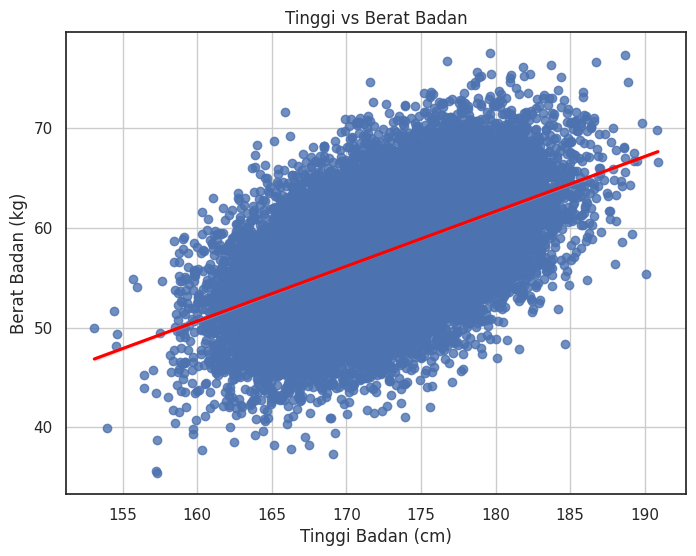

In [74]:
#Visualisasi scatterplot dengan garis regresi
plt.figure(figsize=(8, 6))
sns.regplot(x='Height(Centimeter)', y='Weight(Kilograms)', data=df, ci=95, line_kws={'color': 'red'})
plt.title('Tinggi vs Berat Badan')
plt.xlabel('Tinggi Badan (cm)')
plt.ylabel('Berat Badan (kg)')
plt.grid(True)
plt.show()

# **BAB VIII ANALISIS REGRESI SEDERHANA**

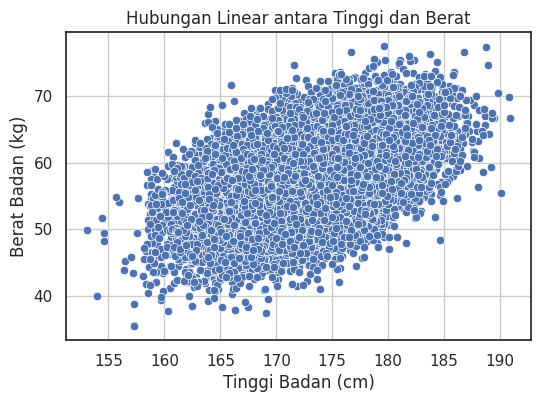

In [75]:
plt.figure(figsize=(6,4))
sns.scatterplot(x='Height(Centimeter)', y='Weight(Kilograms)', data=df)
plt.title('Hubungan Linear antara Tinggi dan Berat')
plt.xlabel('Tinggi Badan (cm)')
plt.ylabel('Berat Badan (kg)')
plt.grid(True)
plt.show()

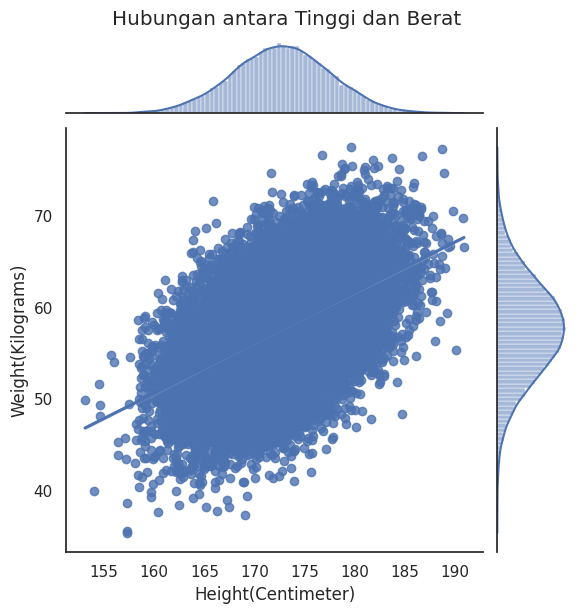

In [76]:
sns.jointplot(data=df, x='Height(Centimeter)', y='Weight(Kilograms)', kind='reg', height=6)
plt.suptitle('Hubungan antara Tinggi dan Berat', y=1.02)
plt.show()

In [77]:
# 1. UJI F - Signifikansi Model Secara Keseluruhan
#    - Hipotesis:
#        H0: Semua koefisien = 0 (model tidak signifikan)
#        H1: Setidaknya satu koefisien ≠ 0 (model signifikan)
#    - Bagian:
#        F-statistic dan Prob (F-statistic)
#    - Jika p-value F < 0.05 → H0 ditolak → model signifikan secara keseluruhan

# 2. UJI t - Signifikansi Tiap Variabel
#    - Hipotesis untuk masing-masing variabel X:
#        H0: Koefisien β = 0 (tidak berpengaruh)
#        H1: Koefisien β ≠ 0 (berpengaruh)
#    Kolom: P>|t|
#    - Jika p-value < 0.05 → H0 ditolak → variabel signifikan memengaruhi Y

# 3. R-squared:
#    - Mengukur seberapa besar variasi Y bisa dijelaskan oleh X
#    - Semakin mendekati 1 → model semakin baik

X = sm.add_constant(df['Height(Centimeter)'])
y = df['Weight(Kilograms)']
model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:      Weight(Kilograms)   R-squared:                       0.253
Model:                            OLS   Adj. R-squared:                  0.253
Method:                 Least Squares   F-statistic:                     8461.
Date:                Wed, 25 Nov 2026   Prob (F-statistic):               0.00
Time:                        02:38:23   Log-Likelihood:                -73471.
No. Observations:               25000   AIC:                         1.469e+05
Df Residuals:                   24998   BIC:                         1.470e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                -37.4557      1

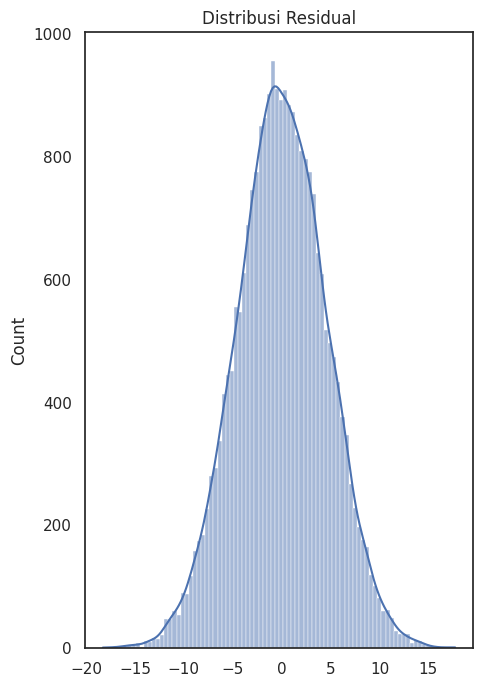

In [78]:
# Histogram
residuals = model.resid
sns.histplot(residuals, kde=True)
plt.title('Distribusi Residual')
plt.show()

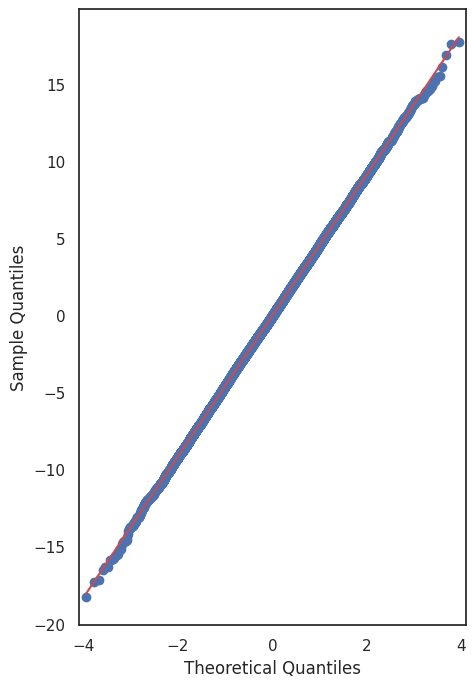

In [79]:
# Q-Q plot
sm.qqplot(residuals, line='s')
plt.show()

In [80]:
# Uji normalitas residual
# Hipotesis:
# H0: Residual model regresi tinggi badan dan berat badan Berdistribusi Normal.
# H1: Residual model regresi tinggi badan dan berat badan Tidak berdistribusi Normal.
stat, p = shapiro(residuals)
print("Uji Normalitas (Shapiro-Wilk):")
print('Statistik = %.3f, P value = %.3f' %(stat, p))
if p > 0.05:
  print('H0: Residual Berdistribusi Normal')
else:
  print('H1: Residual Tidak berdistribusi Normal')

Uji Normalitas (Shapiro-Wilk):
Statistik = 1.000, P value = 0.861
H0: Residual Berdistribusi Normal


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 25000.
  res = hypotest_fun_out(*samples, **kwds)


In [81]:
# Uji Breusch-Pagan
# Hipotesis:
# H0: Residual model regresi tinggi badan dan berat badan Homoskedastik.
# H1: Residual model regresi tinggi badan dan berat badan Heteroskedastik.
bp_test = het_breuschpagan(residuals, model.model.exog)
bp_stat = bp_test[0]
bp_pvalue = bp_test[1]
print(f'Breusch-Pagan Statistic: {bp_stat:.3f}')
print(f'Breusch-Pagan p-value: {bp_pvalue:.3f}')
if bp_pvalue > 0.05:
    print('H0: Residual homoskedastik (varians konstan)')
else:
    print('H1: Residual heteroskedastik (varians tidak konstan)')

Breusch-Pagan Statistic: 3.497
Breusch-Pagan p-value: 0.061
H0: Residual homoskedastik (varians konstan)


In [82]:
# Uji Autokorelasi (Breusch-Godfrey)
# Hipotesis:
# H0: Tidak ada Autokorelasi Residual model regresi tinggi badan dan berat badan.
# H1: Ada Autokorelasi Residual model regresi tinggi badan dan berat badan.
bg_test = acorr_breusch_godfrey(model, nlags=1)
bg_stat = bg_test[0]
bg_pvalue = bg_test[1]
print(f'Breusch-Godfrey Statistic: {bg_stat:.3f}')
print(f'Breusch-Godfrey p-value: {bg_pvalue:.3f}')
if bg_pvalue > 0.05:
    print('H0: Tidak ada autokorelasi residual')
else:
    print('H1: Terdapat autokorelasi residual')

Breusch-Godfrey Statistic: 0.224
Breusch-Godfrey p-value: 0.636
H0: Tidak ada autokorelasi residual


/tmp/ipykernel_1094/1742001111.py:5: FutureWarning: acorr_breusch_godfrey currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  bg_test = acorr_breusch_godfrey(model, nlags=1)


In [83]:
#Regresi
X = df[['Height(Centimeter)']]
y = df['Weight(Kilograms)']
model = LinearRegression()
model.fit(X, y)
intercept = model.intercept_
slope = model.coef_[0]
print(f"Persamaan regresi: berat = {intercept:.2f} + {slope:.2f} × tinggi")

Persamaan regresi: berat = -37.46 + 0.55 × tinggi


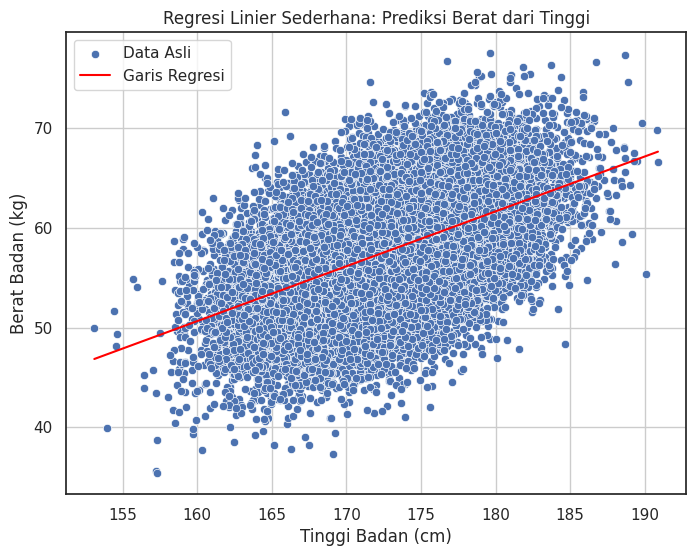

In [84]:
# Visualisasi Hasil Regresi
df['prediksi_berat'] = model.predict(X)
plt.figure(figsize=(8, 6))
sns.scatterplot(x='Height(Centimeter)', y='Weight(Kilograms)', data=df, label='Data Asli')
sns.lineplot(x='Height(Centimeter)', y='prediksi_berat', data=df, color='red', label='Garis Regresi')
plt.xlabel('Tinggi Badan (cm)')
plt.ylabel('Berat Badan (kg)')
plt.title('Regresi Linier Sederhana: Prediksi Berat dari Tinggi')
plt.legend()
plt.grid(True)
plt.show()

# **BAB IX ANALISIS REGRESI BERGANDA**

In [85]:
print(df4.head())

  Species  Weight  Length1  Length2  Length3   Height   Width
0   Bream   242.0     23.2     25.4     30.0  11.5200  4.0200
1   Bream   290.0     24.0     26.3     31.2  12.4800  4.3056
2   Bream   340.0     23.9     26.5     31.1  12.3778  4.6961
3   Bream   363.0     26.3     29.0     33.5  12.7300  4.4555
4   Bream   430.0     26.5     29.0     34.0  12.4440  5.1340


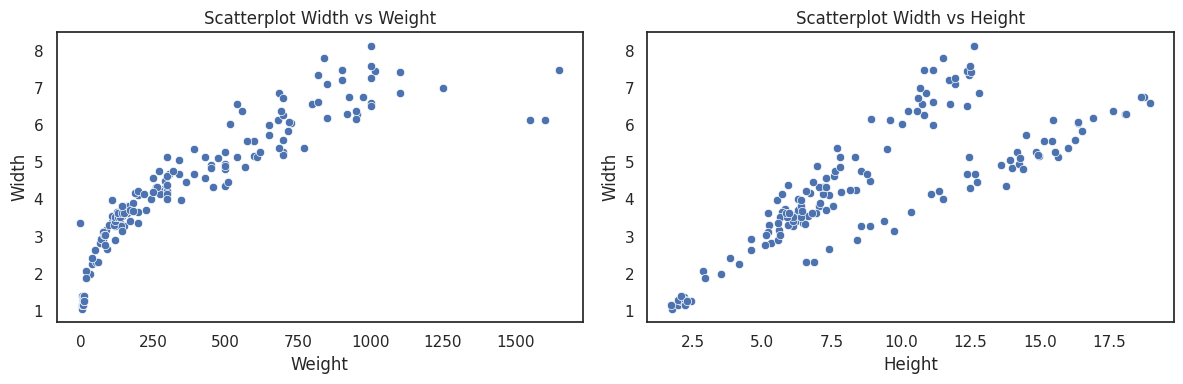

In [86]:
predictors = ['Weight', 'Height']
target = 'Width'
fig, axs = plt.subplots(1, len(predictors), figsize=(6*len(predictors), 4))
for i, var in enumerate(predictors):
    sns.scatterplot(x=var, y=target, data=df4, ax=axs[i])
    axs[i].set_title(f'Scatterplot {target} vs {var}')
    axs[i].set_xlabel(var)
    axs[i].set_ylabel(target)
plt.tight_layout()
plt.show()

In [87]:
# Variabel independen (tanpa konstanta)
X_new = df4[['Weight', 'Height']]
vif_data = pd.DataFrame()
vif_data['feature'] = X_new.columns
vif_data['VIF'] = [variance_inflation_factor(X_new.values, i) for i in range(len(X_new.columns))]
print(vif_data)
for index, row in vif_data.iterrows():
    feature = row['feature']
    vif = row['VIF']
    if vif < 5:
        kategori = "tidak terdapat indikasi multikolinearitas"
    elif vif < 10:
        kategori = "terdapat korelasi cukup tinggi antar variabel"
    else:
        kategori = "terdapat multikolinearitas yang tinggi"
    print(f"{feature} → VIF = {vif:.2f} - {kategori}")

  feature       VIF
0  Weight  2.103829
1  Height  2.103829
Weight → VIF = 2.10 - tidak terdapat indikasi multikolinearitas
Height → VIF = 2.10 - tidak terdapat indikasi multikolinearitas


In [88]:
# 1. UJI F - Signifikansi Model Secara Keseluruhan
#    - Hipotesis:
#        H0: Semua koefisien = 0 (model tidak signifikan)
#        H1: Setidaknya satu koefisien ≠ 0 (model signifikan)
#    - Bagian:
#        F-statistic dan Prob (F-statistic)
#    - Jika p-value F < 0.05 → H0 ditolak → model signifikan secara keseluruhan

# 2. UJI t - Signifikansi Tiap Variabel
#    - Hipotesis untuk masing-masing variabel X:
#        H0: Koefisien β = 0 (tidak berpengaruh)
#        H1: Koefisien β ≠ 0 (berpengaruh)
#    Kolom: P>|t|
#    - Jika p-value < 0.05 → H0 ditolak → variabel signifikan memengaruhi Y

# 3. R-squared:
#    - Mengukur seberapa besar variasi Y bisa dijelaskan oleh X
#    - Semakin mendekati 1 → model semakin baik

# Variabel independen (predictors)
X_new = df4[['Weight', 'Height']]
# Tambahkan intercept (konstanta)
X_new = sm.add_constant(X_new)
# Variabel dependen (target)
y_new = df4['Width']
# Model regresi linier
model_new = sm.OLS(y_new, X_new).fit()
print(model_new.summary())

                            OLS Regression Results                            
Dep. Variable:                  Width   R-squared:                       0.834
Model:                            OLS   Adj. R-squared:                  0.832
Method:                 Least Squares   F-statistic:                     391.0
Date:                Wed, 25 Nov 2026   Prob (F-statistic):           1.70e-61
Time:                        02:38:44   Log-Likelihood:                -165.53
No. Observations:                 159   AIC:                             337.1
Df Residuals:                     156   BIC:                             346.3
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.0665      0.132     15.703      0.0

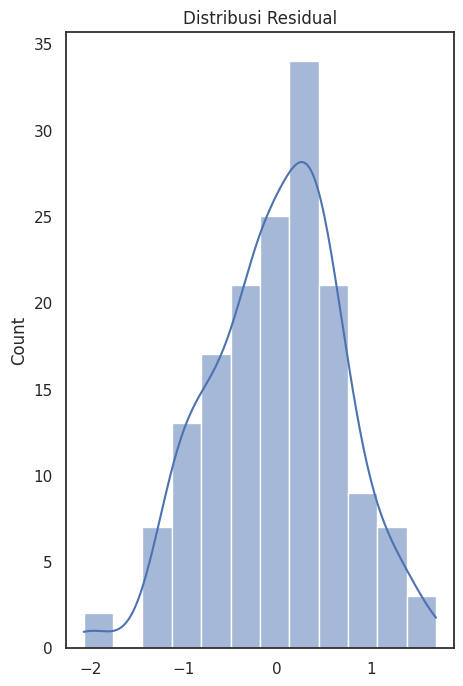

In [89]:
# Histogram
residual = model_new.resid
sns.histplot(residual, kde=True)
plt.title('Distribusi Residual')
plt.show()

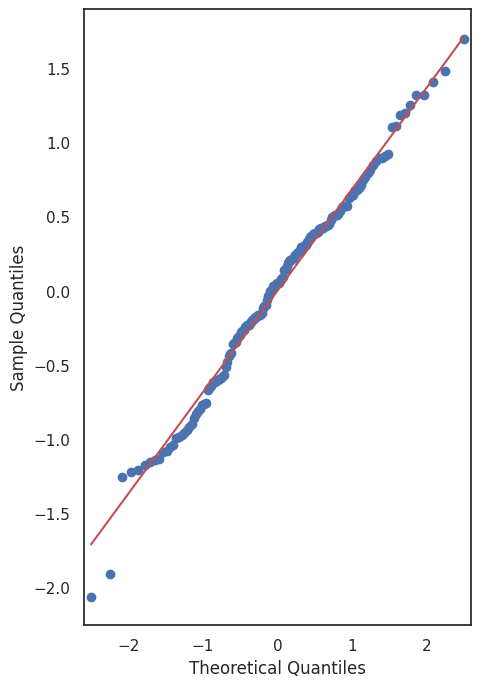

In [90]:
# Q-Q plot
sm.qqplot(residual, line='s')
plt.show()

In [91]:
# Uji normalitas residual
# Hipotesis:
# H0: Residual model regresi tinggi dan berat Berdistribusi Normal.
# H1: Residual model regresi tinggi dan berat Tidak berdistribusi Normal.
stat, p = shapiro(residual)
print("Uji Normalitas (Shapiro-Wilk):")
print('Statistik = %.3f, P value = %.3f' %(stat, p))
if p > 0.05:
  print('H0: Residual Berdistribusi Normal')
else:
  print('H1: Residual Tidak berdistribusi Normal')

Uji Normalitas (Shapiro-Wilk):
Statistik = 0.991, P value = 0.376
H0: Residual Berdistribusi Normal


In [92]:
# Uji Breusch-Pagan
# Hipotesis:
# H0: Residual model regresi tinggi dan berat Homoskedastik.
# H1: Residual model regresi tinggi dan berat Heteroskedastik.
bp_test = het_breuschpagan(model_new.resid, model_new.model.exog)
bp_stat = bp_test[0]
bp_pvalue = bp_test[1]
print(f'Breusch-Pagan Statistic: {bp_stat:.3f}')
print(f'Breusch-Pagan p-value: {bp_pvalue:.3f}')
if bp_pvalue > 0.05:
    print('H0: Residual homoskedastik (varians konstan)')
else:
    print('H1: Residual heteroskedastik (varians tidak konstan)')

Breusch-Pagan Statistic: 45.227
Breusch-Pagan p-value: 0.000
H1: Residual heteroskedastik (varians tidak konstan)


In [93]:
# Uji Autokorelasi (Breusch-Godfrey)
# Hipotesis:
# H0: Tidak ada Autokorelasi Residual model regresi tinggi dan berat.
# H1: Ada Autokorelasi Residual model regresi tinggi dan berat.
bg_test = acorr_breusch_godfrey(model_new, nlags=1)
bg_stat = bg_test[0]
bg_pvalue = bg_test[1]
print(f'Breusch-Godfrey Statistic: {bg_stat:.3f}')
print(f'Breusch-Godfrey p-value: {bg_pvalue:.3f}')
if bg_pvalue > 0.05:
    print('H0: Tidak ada autokorelasi residual')
else:
    print('H1: Terdapat autokorelasi residual')

Breusch-Godfrey Statistic: 109.183
Breusch-Godfrey p-value: 0.000
H1: Terdapat autokorelasi residual


/tmp/ipykernel_1094/3429002102.py:5: FutureWarning: acorr_breusch_godfrey currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  bg_test = acorr_breusch_godfrey(model_new, nlags=1)


In [95]:
# Persamaan Regeresi
coefficients = model_new.params
target_var = 'lebar ikan'
equation = f"{target_var} = {coefficients.iloc[0]:.4f}"
for var, coef in coefficients[1:].items():
    sign = " + " if coef >= 0 else " - "
    equation += f"{sign}{abs(coef):.4f} × {var}"
print("Persamaan regresi:")
print(equation)

Persamaan regresi:
lebar ikan = 2.0665 + 0.0031 × Weight + 0.1247 × Height
